# 02 – Local vocabulary layer (South African credentials and terms)

**Step 1 (local layer) of the implementation plan.**

This notebook builds what makes *local-aware mode* local:

1. Loads the **local vocabulary**: South African credentials (matric, NC(V), N1–N6, trade tests, licence codes, professional registrations, mining certificates) and local workplace terms (PERSAL, BAS, LOGIS, PFMA, MHSA, Batho Pele…).
2. Builds an **extractor** that finds these in any text, and tests it.
3. Loads the **credential equivalence rules** (e.g. NC(V) Level 4 satisfies a Grade 12 requirement; Code C1 covers Code B) and builds a `satisfies()` function.
4. Applies the extractor to the 427 Limpopo jobs and measures **how often jobs ask for local credentials**.
5. Checks **how much of the local vocabulary ESCO already covers**. This is evidence for why a local layer is needed.
6. Saves the combined vocabulary for the matcher.

Inputs: `data/raw/local/local_vocabulary.csv`, `data/raw/local/equivalences.csv` (both editable in Excel; save as **CSV UTF-8**), plus the outputs of notebook 01.

In [1]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
LOCAL = ROOT / "data" / "raw" / "local"
PROCESSED = ROOT / "data" / "processed"

def read_csv_any_encoding(path):
    for enc in ("utf-8-sig", "mac_roman"):
        try:
            return pd.read_csv(path, dtype=str, encoding=enc).fillna("")
        except UnicodeDecodeError:
            continue

vocab = read_csv_any_encoding(LOCAL / "local_vocabulary.csv")
equiv = read_csv_any_encoding(LOCAL / "equivalences.csv")
jobs = pd.read_csv(PROCESSED / "jobs_clean.csv", dtype=str).fillna("")
esco_vocab = pd.read_csv(PROCESSED / "vocab_generic.csv", dtype=str).fillna("")

print(f"Local vocabulary: {len(vocab)} entries ({(vocab.kind=='credential').sum()} credentials, {(vocab.kind=='term').sum()} terms)")
print(f"Equivalence rules: {len(equiv)}")
print(f"Jobs: {len(jobs)}   ESCO labels: {len(esco_vocab):,}")
vocab.groupby(["kind", "category"]).size().rename("entries").to_frame()

Local vocabulary: 85 entries (58 credentials, 27 terms)
Equivalence rules: 26
Jobs: 427   ESCO labels: 100,350


entries
kind       category               
credential health                3
           higher                4
           licence               7
           mining                9
           occupational          3
           public_service        2
           registration         14
           safety                3
           school                2
           trade                 1
           tvet                 10
term       framework             5
           legislation          12
           system               10

## 1. Build the extractor

Each entry has several **aliases** separated by `;` (e.g. *Grade 12; Matric; National Senior Certificate; NSC*).
Plain aliases are matched as whole words, ignoring case unless `case_sensitive = 1`. Aliases starting with `re:` are regular expressions, used for codes like `N6` or `Code C` (not `Code C1`).

In [2]:
def alias_to_regex(alias):
    alias = alias.strip()
    if alias.lower().startswith("re:"):
        return alias[3:]
    words = [re.escape(w) for w in alias.split()]
    body = r"\s+".join(words).replace(r"\'", "['’]")
    return rf"(?<![A-Za-z0-9]){body}(?![A-Za-z0-9])"

MATCHERS = []
for _, r in vocab.iterrows():
    flags = 0 if r["case_sensitive"] == "1" else re.IGNORECASE
    pats = [alias_to_regex(a) for a in r["aliases"].split(";") if a.strip()]
    MATCHERS.append((r["id"], re.compile("|".join(f"(?:{p})" for p in pats), flags)))

def find_local(text):
    """Return the set of local vocabulary ids mentioned in text."""
    return {vid for vid, rx in MATCHERS if rx.search(text)}

LABEL = dict(zip(vocab["id"], vocab["label"]))
CATEGORY = dict(zip(vocab["id"], vocab["category"]))
print(f"Compiled {len(MATCHERS)} matchers")

Compiled 85 matchers


### Tests
Each line checks one tricky case. If any fails, fix the alias in `local_vocabulary.csv` and re-run.

In [3]:
TESTS = [
    ("Grade 12 or NQF Level 4 equivalent",               {"GR12"},        set()),
    ("Matric; Code 10 licence with PrDP",                 {"GR12", "LIC_C1", "PRDP"}, set()),
    ("valid Code EB driver's licence",                    {"LIC_EB", "LIC_ANY"}, {"LIC_B"}),
    ("Code C1 licence",                                   {"LIC_C1"},      {"LIC_C"}),
    ("N4/S2 engineering certificate and trade test",      {"N4", "TRADE_TEST"}, set()),
    ("NQF 6 qualification in Finance",                    {"DIPLOMA"},     {"N6"}),
    ("Red Seal Fitter and Turner",                        {"TRADE_TEST"},  set()),
    ("contract administration under GCC, FIDIC and COTO", {"FW_CONTRACTS", "FW_ROADSPEC"}, {"MIN_GCC"}),
    ("valid GCC (Factories) certificate",                 {"MIN_GCC"},     set()),
    ("knowledge of PFMA, BAS, PERSAL and LOGIS",          {"LAW_PFMA", "SYS_BAS", "SYS_PERSAL", "SYS_LOGIS"}, set()),
    ("HPCSA registration as a Physiotherapist",           {"REG_HPCSA"},   set()),
    ("NC(V) Level 4 in Office Administration",            {"NCV_L4"},      set()),
    ("Basic R425 nursing qualification; SANC registration", {"NURSE_R425", "REG_SANC"}, set()),
]
failures = 0
for text, must, must_not in TESTS:
    got = find_local(text)
    ok = must <= got and not (must_not & got)
    failures += not ok
    print("PASS" if ok else "FAIL", "|", text, "->", sorted(got))
print(f"\n{len(TESTS) - failures}/{len(TESTS)} tests passed")

PASS | Grade 12 or NQF Level 4 equivalent -> ['GR12']
PASS | Matric; Code 10 licence with PrDP -> ['GR12', 'LIC_C1', 'PRDP']
PASS | valid Code EB driver's licence -> ['LIC_ANY', 'LIC_EB']
PASS | Code C1 licence -> ['LIC_C1']
PASS | N4/S2 engineering certificate and trade test -> ['N4', 'TRADE_TEST']
PASS | NQF 6 qualification in Finance -> ['DIPLOMA']
PASS | Red Seal Fitter and Turner -> ['TRADE_TEST']
PASS | contract administration under GCC, FIDIC and COTO -> ['FW_CONTRACTS', 'FW_ROADSPEC']
PASS | valid GCC (Factories) certificate -> ['MIN_GCC']
PASS | knowledge of PFMA, BAS, PERSAL and LOGIS -> ['LAW_PFMA', 'SYS_BAS', 'SYS_LOGIS', 'SYS_PERSAL']
PASS | HPCSA registration as a Physiotherapist -> ['REG_HPCSA']
PASS | NC(V) Level 4 in Office Administration -> ['NCV_L4']
PASS | Basic R425 nursing qualification; SANC registration -> ['NURSE_R425', 'REG_SANC']

13/13 tests passed


## 2. Credential equivalences

`equivalences.csv` says which credential satisfies which requirement, e.g. `requirement GR12 ← satisfied by NCV_L4`.
Rules chain: an EC licence covers C, which covers C1, which covers B, so EC satisfies a "Code 08 (B)" requirement.
Rules with `verified = 0` still need checking against official sources (DHET, SAQA, QCTO); they are flagged below.

In [4]:
SATISFIES = {}                                        # credential -> set of requirements it meets
for _, r in equiv.iterrows():
    SATISFIES.setdefault(r["satisfied_by_id"], set()).add(r["requirement_id"])

def closure(creds):
    """All requirements a set of credentials meets, following rules transitively."""
    met, stack = set(creds), list(creds)
    while stack:
        for req in SATISFIES.get(stack.pop(), ()):
            if req not in met:
                met.add(req); stack.append(req)
    return met

def satisfies(candidate_creds, required):
    return required in closure(candidate_creds)

# Demonstration: what generic matching misses
candidate = {"NCV_L4", "LIC_C1"}
for req in ["GR12", "LIC_B", "LIC_ANY", "DIPLOMA"]:
    print(f"Candidate {sorted(candidate)} meets {req:8s} ({LABEL[req]}): {satisfies(candidate, req)}")

print("\nRules still to verify:")
equiv.loc[equiv["verified"] != "1", ["requirement_id", "satisfied_by_id", "condition", "notes"]]

Candidate ['LIC_C1', 'NCV_L4'] meets GR12     (Grade 12 / Matric (National Senior Certificate)): True
Candidate ['LIC_C1', 'NCV_L4'] meets LIC_B    (Code B (old Code 08)): True
Candidate ['LIC_C1', 'NCV_L4'] meets LIC_ANY  (Valid driver's licence (any code)): True
Candidate ['LIC_C1', 'NCV_L4'] meets DIPLOMA  (National Diploma / NQF 6 qualification): False

Rules still to verify:


,requirement_id,satisfied_by_id,condition,notes
1,GR12,N3,Technical and trade roles,Mining trade ads accept 'Grade 12 or N3 trade ...
3,BASIC_ED,NCV_L2,,To verify
13,DIPLOMA,NDIP_N,,National N Diploma treated as an NQF 6 diploma...
18,GR12,TRADE_TEST,Trade roles,To verify; artisans usually hold N2/N3 or Grad...
25,MIN_COMPETENT,MIN_SUPERVISOR,,To verify


## 3. How often do Limpopo jobs ask for local credentials?

We run the extractor over every job description. Note: the extractor finds mentions; it does not yet tell *required* from *advantageous* (e.g. "Honours an advantage"). We handle that in the matching notebook.

In [5]:
jobs["local_ids"] = jobs["description"].map(find_local)

long = (jobs[["job_id", "district", "source", "local_ids"]]
        .explode("local_ids").dropna(subset=["local_ids"])
        .rename(columns={"local_ids": "local_id"}))
long["category"] = long["local_id"].map(CATEGORY)
long["kind"] = long["local_id"].map(dict(zip(vocab["id"], vocab["kind"])))

TERM_CATS = ("system", "legislation", "framework")
GENERIC = {"LIC_ANY", "HIGHER_CERT", "DIPLOMA", "DEGREE", "HONOURS"}   # found in any country's adverts
has_sa_cred = jobs["local_ids"].map(lambda s: any(CATEGORY[i] not in TERM_CATS and i not in GENERIC for i in s))
has_term = jobs["local_ids"].map(lambda s: any(CATEGORY[i] in TERM_CATS for i in s))
jobs["sa_specific"] = has_sa_cred | has_term

print(f"Jobs mentioning a South Africa-specific credential (matric, N-levels, licence codes, SANC, trade test...): {has_sa_cred.mean():.0%}")
print(f"Jobs mentioning a local term (PERSAL, PFMA, MHSA, Batho Pele...): {has_term.mean():.0%}")
print(f"Jobs mentioning either: {jobs['sa_specific'].mean():.0%}")
print("\nBy source:")
print(jobs.groupby("source")["sa_specific"].mean().map("{:.0%}".format).to_string())

top = (long.groupby("local_id")["job_id"].nunique().sort_values(ascending=False).head(20)
       .rename("jobs").to_frame())
top["label"] = top.index.map(LABEL)
top["share"] = (top["jobs"] / len(jobs)).map("{:.0%}".format)
top

Jobs mentioning a South Africa-specific credential (matric, N-levels, licence codes, SANC, trade test...): 73%
Jobs mentioning a local term (PERSAL, PFMA, MHSA, Batho Pele...): 38%
Jobs mentioning either: 81%

By source:
source
DPSA    81%
PNet    81%


,jobs,label,share
local_id,,,
LIC_ANY,278,Valid driver's licence (any code),65%
DIPLOMA,230,National Diploma / NQF 6 qualification,54%
GR12,172,Grade 12 / Matric (National Senior Certificate),40%
DEGREE,107,Bachelor's degree / NQF 7,25%
LAW_PFMA,65,PFMA,15%
SYS_PERSAL,33,PERSAL (government payroll/HR system),8%
SYS_BAS,25,BAS (Basic Accounting System),6%
REG_HPCSA,23,HPCSA registration,5%
LAW_TREASURY,23,Treasury Regulations,5%


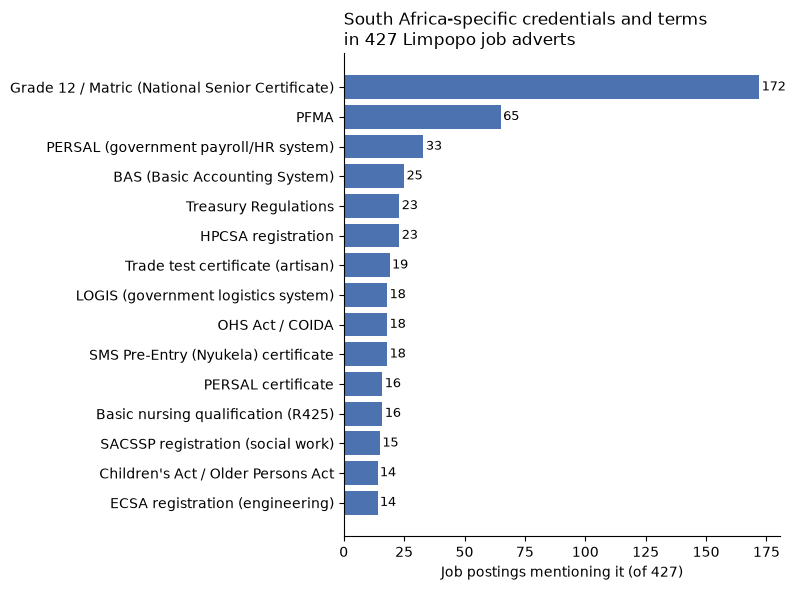

In [6]:
# Chart only the South Africa-specific entries (leave out generic degree/diploma/'any licence')
sa_top = (long[~long["local_id"].isin(GENERIC)].groupby("local_id")["job_id"].nunique()
          .sort_values(ascending=False).head(15))
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh([LABEL[i] for i in sa_top.index[::-1]], sa_top.values[::-1], color="#4C72B0")
for y, v in enumerate(sa_top.values[::-1]):
    ax.text(v + 1, y, str(v), va="center", fontsize=9)
ax.set_xlabel("Job postings mentioning it (of %d)" % len(jobs))
ax.set_title("South Africa-specific credentials and terms\nin %d Limpopo job adverts" % len(jobs), loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
(ROOT / "figures").mkdir(exist_ok=True)
plt.savefig(ROOT / "figures" / "02_local_terms_frequency.png", dpi=200)
plt.show()

In [7]:
# By category and source
cat = (long.groupby(["category", "source"])["job_id"].nunique().unstack(fill_value=0))
cat["% of all jobs"] = (long.groupby("category")["job_id"].nunique() / len(jobs) * 100).round(0)
cat.sort_values("% of all jobs", ascending=False)

source,DPSA,PNet,% of all jobs
category,,,
higher,292,26,74.0
licence,256,24,66.0
school,145,35,42.0
legislation,102,10,26.0
registration,82,15,23.0
system,54,9,15.0
public_service,34,0,8.0
health,18,3,5.0
mining,1,19,5.0


## 4. How much of this does ESCO already know?

For each local entry we check whether any of its aliases appears in ESCO's skill labels. Entries ESCO lacks can only be recognised in local-aware mode.

In [8]:
esco_text = "\n".join(esco_vocab["label"].str.lower())

def in_esco(row):
    for a in row["aliases"].split(";"):
        a = a.strip()
        if not a or a.lower().startswith("re:"):
            continue
        if re.search(alias_to_regex(a), esco_text, flags=re.IGNORECASE):
            return True
    return False

vocab["in_esco"] = vocab.apply(in_esco, axis=1)
used_ids = set(long["local_id"])
cov = vocab[vocab["id"].isin(used_ids)]
print(f"Local entries found in the Limpopo jobs: {len(cov)}")
print(f"... of which ESCO has no matching label: {(~cov['in_esco']).sum()} ({(~cov['in_esco']).mean():.0%})")
cov.groupby("category")["in_esco"].agg(entries="size", in_esco="sum").assign(
    missing_from_esco=lambda d: d["entries"] - d["in_esco"])

Local entries found in the Limpopo jobs: 78
... of which ESCO has no matching label: 72 (92%)


,entries,in_esco,missing_from_esco
category,,,
framework,5,0,5
health,3,0,3
higher,4,1,3
legislation,12,0,12
licence,5,1,4
mining,9,0,9
occupational,3,1,2
public_service,2,0,2
registration,14,0,14


## 5. Save outputs

- `vocab_local.csv`: one row per alias, same columns as `vocab_generic.csv` plus `category`, with `layer = local`.
- `vocab_combined.csv`: generic + local, used by local-aware mode.
- `job_local_requirements.csv`: which local credentials and terms each job mentions.
- `local_coverage.csv`: which local entries ESCO lacks.

In [9]:
rows = []
for _, r in vocab.iterrows():
    for a in r["aliases"].split(";"):
        a = a.strip()
        if a and not a.lower().startswith("re:"):
            rows.append({"skill_id": "local:" + r["id"], "skill_name": r["label"], "label": a,
                         "label_type": "alternative", "label_lower": a.lower(), "layer": "local",
                         "category": r["category"]})
    rows.append({"skill_id": "local:" + r["id"], "skill_name": r["label"], "label": r["label"],
                 "label_type": "preferred", "label_lower": r["label"].lower(), "layer": "local",
                 "category": r["category"]})
vocab_local = pd.DataFrame(rows).drop_duplicates(["skill_id", "label_lower"])
vocab_combined = pd.concat([esco_vocab.assign(category="esco"), vocab_local], ignore_index=True)

vocab_local.to_csv(PROCESSED / "vocab_local.csv", index=False)
vocab_combined.to_csv(PROCESSED / "vocab_combined.csv", index=False)
long.to_csv(PROCESSED / "job_local_requirements.csv", index=False)
vocab[["id", "label", "kind", "category", "in_esco", "verified"]].to_csv(PROCESSED / "local_coverage.csv", index=False)

for f in ["vocab_local.csv", "vocab_combined.csv", "job_local_requirements.csv", "local_coverage.csv"]:
    print(f"{f:30s} {(PROCESSED / f).stat().st_size/1024:8.0f} KB")

vocab_local.csv                      27 KB
vocab_combined.csv                18256 KB
job_local_requirements.csv           69 KB
local_coverage.csv                    5 KB


**Next notebook:** `03_synthetic_candidates.ipynb`: generates Limpopo job seekers from ESCO occupations and local credentials, with home towns, time and budget limits, and group attributes for the fairness analysis.